In [1]:
import os
import pandas as pd
import joblib
import numpy as np
import matplotlib.pyplot as plt
from FeaturesTemporais import FeaturesTemporais
from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error, root_mean_squared_error
from lightgbm import LGBMRegressor
import shap

def get_csv_root():
    try:
        BASE_DIR = os.path.dirname(os.path.abspath(__file__))
    except NameError:
        BASE_DIR = os.getcwd()
    return os.path.join(BASE_DIR, "..", "processado")

shap.initjs()

/home/carlosz/Documentos/TCC_Predicao_glicemia/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# ---- 1. Carregar ----
df_treinamento = pd.read_csv(os.path.join(get_csv_root(), "treinamento_app.csv"))
df_testes = pd.read_csv(os.path.join(get_csv_root(), "testes_app.csv"))

columns_used = [c for c in df_treinamento.columns]
# columns_used = ['ts', 'metodo_medida', 'glucose_level', 'basal', 'bolus_type',
#        'bolus_dose', 'meal_type', 'meal_carbs', 'meal_time',
#        'exercise_intensity', 'doing_exercise', 'target',
#        'iob', 'cob']

df_tr = df_treinamento[columns_used].copy()
df_val = df_testes[columns_used].copy()

df_tr = df_tr.rename(columns={"ts": "timestamp"})
df_val = df_val.rename(columns={"ts": "timestamp"})

print(df_tr.columns)

Index(['glucose_level', 'metodo_medida', 'timestamp', 'meal_carbs',
       'meal_type', 'bolus_dose', 'bolus_type', 'basal', 'doing_exercise',
       'exercise_intensity', 'tempo_desde_ultima_medicao',
       'glucose_delta_desde_ultima', 'iob', 'cob', 'is_cgm', 'target_2h'],
      dtype='str')


In [3]:
# ---- 2. Regra de negócio (igual antes) ----
for df in (df_tr, df_val):
    df['meal_carbs'] = df['meal_carbs'].fillna(0)
    df['exercise_intensity'] = df['exercise_intensity'].fillna(0)
    df.loc[df["meal_carbs"] == 0, "meal_type"] = "Fasting"

# ---- 2.5. Remover linhas sem alvo ----
print(f"Tr antes: {len(df_treinamento)}")

for df in (df_tr, df_val):
    df.dropna(subset=["target_2h", "glucose_level"], inplace=True)
    df.reset_index(drop=True, inplace=True)

print(f"Tr depois: {len(df_tr)}")
print(f"Perdidas: {len(df_treinamento) - len(df_tr)} ({100*(1 - len(df_tr)/len(df_treinamento)):.1f}%)")

# df_tr.info()
# df_val.info()


Tr antes: 6653
Tr depois: 6653
Perdidas: 0 (0.0%)


In [4]:
# ---- 3. Separar X e y ----
y_tr = df_tr["target_2h"]
X_tr = df_tr.drop(columns=["target_2h"])

y_val = df_val["target_2h"]
X_val = df_val.drop(columns=["target_2h"])

display(X_tr)

,glucose_level,metodo_medida,timestamp,meal_carbs,meal_type,bolus_dose,bolus_type,basal,doing_exercise,exercise_intensity,tempo_desde_ultima_medicao,glucose_delta_desde_ultima,iob,cob,is_cgm
0,80.0,finger_stick,2027-05-19 11:35:00,0.0,Fasting,0.0,NaN,0.95,False,0.0,15.0,0.0,0.000000,0.000000,0
1,137.0,CGM,2027-05-19 12:40:00,0.0,Fasting,0.8,square dual,1.90,False,0.0,65.0,57.0,5.497917,0.000000,1
2,128.0,CGM,2027-05-19 13:15:00,0.0,Fasting,0.0,NaN,0.95,False,0.0,35.0,-9.0,9.029167,0.000000,1
3,71.0,finger_stick,2027-05-19 16:20:00,0.0,Fasting,0.0,NaN,0.00,False,0.0,185.0,-57.0,0.816667,0.000000,0
4,54.0,CGM,2027-05-19 16:25:00,0.0,Fasting,0.0,NaN,0.00,False,0.0,5.0,-17.0,0.700000,0.000000,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6648,98.0,CGM,2027-05-26 09:25:00,0.0,Fasting,0.0,NaN,0.60,False,0.0,120.0,-73.0,1.575000,6.666667,1
6649,128.0,finger_stick,2027-05-26 16:20:00,0.0,Fasting,0.0,NaN,0.60,False,0.0,415.0,30.0,0.000000,8.305556,0
6650,132.0,CGM,2027-05-26 19:40:00,7.0,Snack,0.0,NaN,0.60,False,0.0,200.0,4.0,2.916667,31.500000,1
6651,134.0,CGM,2027-05-26 20:45:00,0.0,Fasting,0.0,NaN,0.60,False,0.0,65.0,2.0,1.833333,13.805556,1


In [5]:
# ---- 4. Identificar colunas numéricas e categóricas ----
num_cols = X_tr.select_dtypes(include=["int64", "float64", "bool"]).columns.tolist()
cat_cols = [c for c in X_tr.select_dtypes(include=["object", "category"]).columns if c != "timestamp"]


print("Numéricas:", num_cols)
print("Categóricas:", cat_cols)

Numéricas: ['glucose_level', 'meal_carbs', 'bolus_dose', 'basal', 'doing_exercise', 'exercise_intensity', 'tempo_desde_ultima_medicao', 'glucose_delta_desde_ultima', 'iob', 'cob', 'is_cgm']
Categóricas: ['metodo_medida', 'meal_type', 'bolus_type']


/tmp/ipykernel_81529/284490340.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = [c for c in X_tr.select_dtypes(include=["object", "category"]).columns if c != "timestamp"]


In [6]:
# ---- 5. Pipeline ----
preprocessador = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"), num_cols),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]), cat_cols),
    ],
    remainder="passthrough",   
)

pipeline = Pipeline([
    ("tempo", FeaturesTemporais(coluna_timestamp="timestamp")),
    ("preprocessador", preprocessador),
    ("rf", RandomForestRegressor(
        n_estimators=10000,
        min_samples_leaf=10,
        random_state=0,
        n_jobs=-1,
    )),
])

pipeline.fit(X_tr, y_tr)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tempo', ...), ('preprocessador', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,coluna_timestamp,'timestamp'
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshol

In [7]:
# 'pipeline' é o objeto já treinado (Pipeline([... , ('rf', RandomForestRegressor())]))
rf = pipeline.named_steps["rf"]

# Aplica todas as transformações (FeaturesTemporais + ColumnTransformer)
# O [:-1] pega tudo menos o 'rf'
X_val_transformed = pipeline[:-1].transform(X_val)

# Obtém os nomes das features pós-transformação
# (com remainder='passthrough', os nomes terão o prefixo 'remainder__')
feature_names = pipeline.named_steps["preprocessador"].get_feature_names_out()

print(f"Formato da matriz transformada: {X_val_transformed.shape}")
print(f"Primeiros nomes: {feature_names[:5]}")

Formato da matriz transformada: (1457, 32)
Primeiros nomes: ['num__glucose_level' 'num__meal_carbs' 'num__bolus_dose' 'num__basal'
 'num__doing_exercise']


In [8]:
explainer = shap.TreeExplainer(rf)
shap_values = explainer.shap_values(X_val_transformed)

# Para regressão, shap_values é um array 2D (n_amostras, n_features)
print(shap_values.shape)  # (n_amostras, n_features)

(1457, 32)


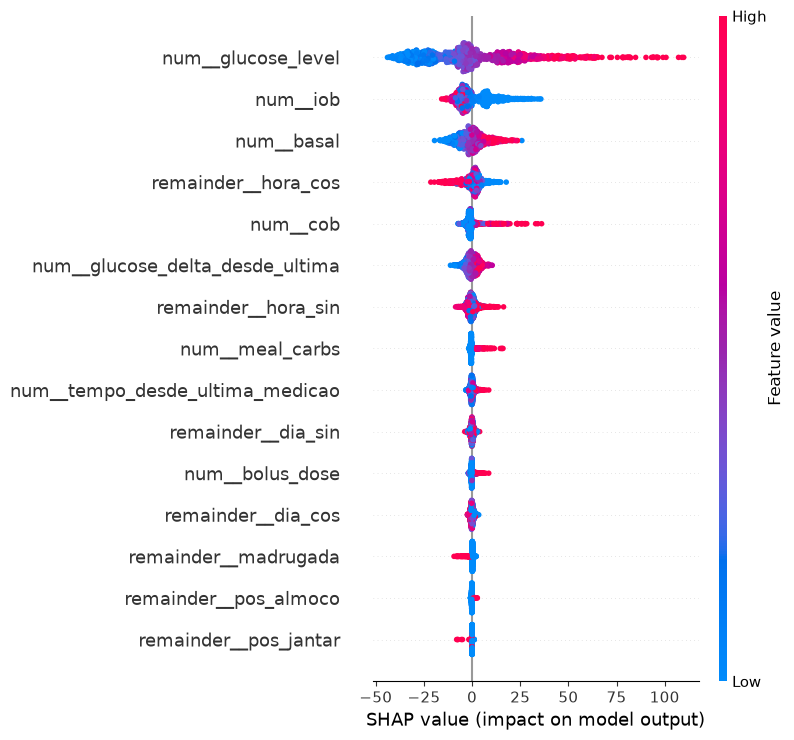

In [9]:
shap.summary_plot(
    shap_values,
    X_val_transformed,
    feature_names=feature_names,
    max_display=15,
    show=True,
)

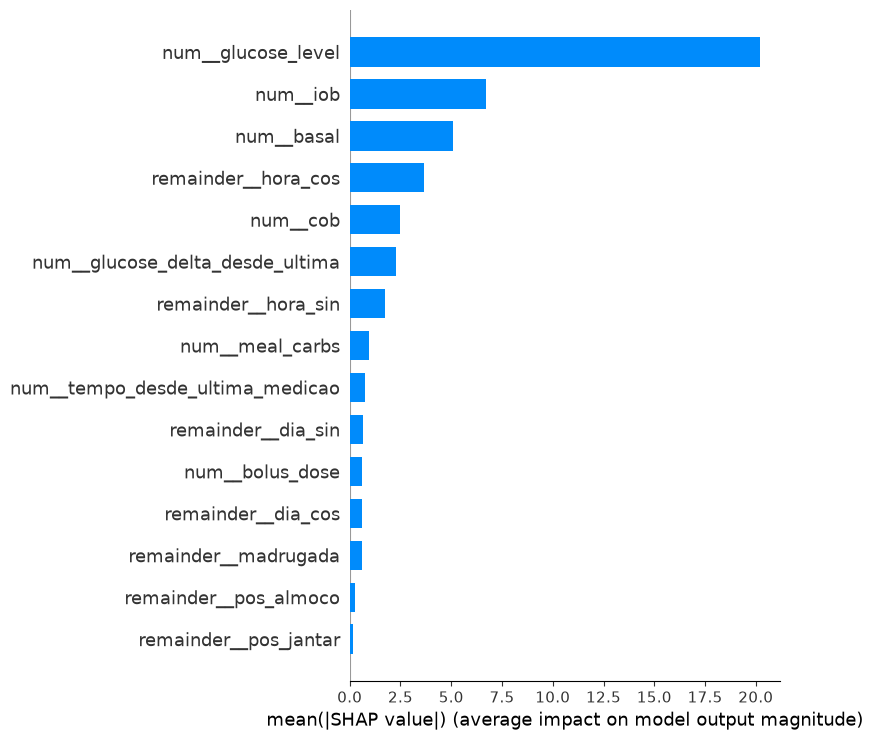

In [10]:
shap.summary_plot(
    shap_values,
    X_val_transformed,
    feature_names=feature_names,
    plot_type="bar",
    max_display=15,
)

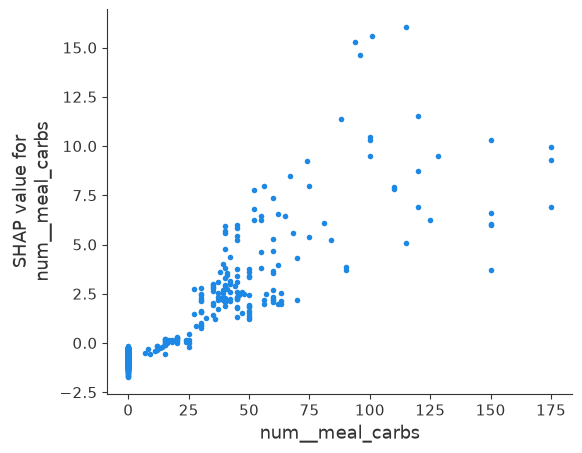

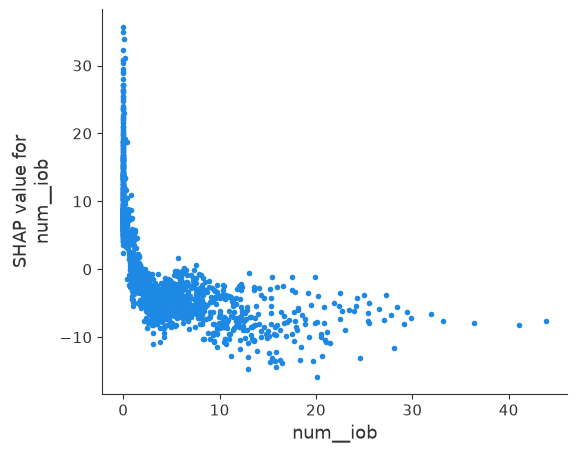

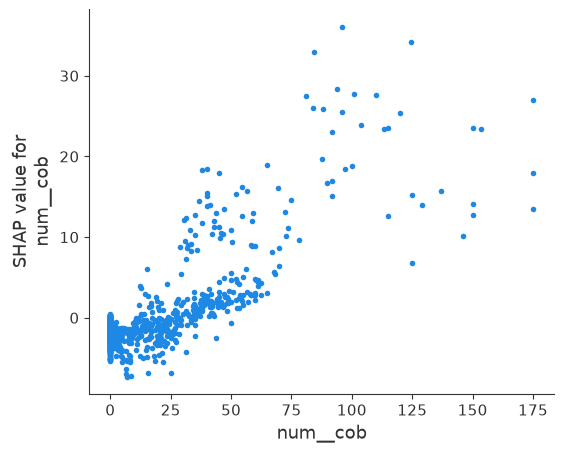

In [16]:
# Exemplo: como o IOB afeta a predição?
shap.dependence_plot(
    "num__meal_carbs",
    shap_values,
    X_val_transformed,
    feature_names=feature_names,
    interaction_index=None,   # ou "auto" para detectar interações
)

# Exemplo: como o IOB afeta a predição?
shap.dependence_plot(
    "num__iob",
    shap_values,
    X_val_transformed,
    feature_names=feature_names,
    interaction_index=None,   # ou "auto" para detectar interações
)
# Exemplo: como o IOB afeta a predição?
shap.dependence_plot(
    "num__cob",
    shap_values,
    X_val_transformed,
    feature_names=feature_names,
    interaction_index=None,   # ou "auto" para detectar interações
)



In [17]:
# ---- 6. Avaliar ----
p = pipeline.predict(X_val)
mse = mean_squared_error(y_val, p)
rmse = root_mean_squared_error(y_val, p)
print(f"MSE: {mse}")
print(f"RMSE: {rmse}")

MSE: 2821.886339682599
RMSE: 53.121430135893355


In [18]:
# 1. Contexto de escala
print(y_tr.describe())
print(f"std target: {y_tr.std():.2f}")

# 2. Baselines

media_tr = y_tr.mean()
rmse_media = root_mean_squared_error(y_val, [media_tr] * len(y_val))
rmse_persist = root_mean_squared_error(y_val, X_val["glucose_level"])
print(f"RMSE chutando a média:      {rmse_media:.2f}")
print(f"RMSE persistência:          {rmse_persist:.2f}")
print(f"RMSE do seu RF:             {rmse:.2f}")


# 3. Importância
rf = pipeline.named_steps["rf"]
nomes = pipeline.named_steps["preprocessador"].get_feature_names_out()
importancias = pd.Series(rf.feature_importances_, index=nomes).sort_values(ascending=False)
print(importancias.head(25))

count    6653.000000
mean      159.641064
std        61.252029
min        40.000000
25%       114.000000
50%       153.000000
75%       197.000000
max       400.000000
Name: target_2h, dtype: float64
std target: 61.25
RMSE chutando a média:      62.40
RMSE persistência:          65.17
RMSE do seu RF:             53.12
num__glucose_level                 0.392297
num__iob                           0.091593
num__basal                         0.087368
remainder__hora_cos                0.084376
remainder__hora_sin                0.063566
num__cob                           0.060716
num__glucose_delta_desde_ultima    0.058342
num__tempo_desde_ultima_medicao    0.044388
remainder__dia_sin                 0.028619
remainder__dia_cos                 0.018335
num__bolus_dose                    0.018230
num__meal_carbs                    0.014956
remainder__madrugada               0.004873
cat__bolus_type_normal             0.003785
remainder__pos_jantar              0.003461
remainder__pos_cafe 

In [ ]:
y_pred = pipeline.predict(X_val)
print("Target: media", y_val.mean(), "std", y_val.std())
print("Pred:   media", y_pred.mean(), "std", y_pred.std())
print("Pred min", y_pred.min(), "max", y_pred.max())

# y_val.mean() ≈ y_pred.mean() (modelo calibrado, sem viés sistemático)

# y_pred.std() < y_val.std() (modelo comprime — regressão pra média, normal)

# y_pred.min/max dentro de 30-450 (não está extrapolando)

# Se y_pred.mean() for muito diferente de y_val.mean(), o modelo está enviesado — pode ser porque a distribuição treino/teste é diferente.

In [ ]:
residuals = np.abs(y_val - y_pred)
X_val_copy = X_val.copy()
X_val_copy["erro"] = residuals
X_val_copy["is_cgm"] = df_val.loc[X_val.index, "is_cgm"].values if "is_cgm" in df_val else 0
X_val_copy["hora"] = pd.to_datetime(X_val["timestamp"]).dt.hour

print("Erro por origem:")
print(X_val_copy.groupby("is_cgm")["erro"].agg(["mean", "count"]))

print("\nErro por faixa de glicose atual:")
X_val_copy["faixa"] = pd.cut(X_val_copy["glucose_level"], bins=[0, 70, 180, 250, 400], labels=["hipo", "normal", "alta", "muito_alta"])
print(X_val_copy.groupby("faixa")["erro"].agg(["mean", "count"]))

# Erro em hipo (glicose < 70) muito maior que em normal? Sinal de alerta clínico — o modelo erra justamente nos casos críticos.

# Erro em finger_stick ≈ erro em CGM? Se CGM for muito melhor, o is_cgm está virando atalho.

In [ ]:
# ---- 7. Salvar ----
joblib.dump(pipeline, "modelo_rf_app.joblib")
print("Modelo salvo em modelo_rf_app.joblib")